<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Final project: Part 1</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



# Install and import libraries.

In [1]:
!pip install -q -U transformers peft accelerate datasets bitsandbytes

In [2]:
!pip install trl

Make sure you have installed basic libraries (numpy, pandas, torch, matplotlib) as well.

In [3]:
import os
import torch
from datasets import load_dataset, Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    logging,
)
from peft import LoraConfig, PromptTuningConfig, PromptTuningInit, get_peft_model, PeftModel

In [4]:
import trl


To download the dataset and loading the Gemma2 model, you have to user your hugging-face token. 

In [5]:
os.environ["HF_TOKEN"] = '<YOUR_TOKEN_HERE>'
os.environ["HF_TOKEN"] = 'YOUR_HF_TOKEN'

# Part 1

## Download and analyze the dataset
First, let's load the dataset. In my analysis, some of the rows in the jsonl file were corrupted! So We will detect and eliminate those rows!

In [6]:
import json
from collections import Counter
import os
from huggingface_hub import hf_hub_download

def download_dataset_from_hf(repo_id, filename):
    """
    Downloads a dataset file from the Hugging Face Hub.
    Returns the local file path.
    """
    print(f"Downloading '{filename}' from repo '{repo_id}'...")
    try:
        file_path = hf_hub_download(repo_id=repo_id, filename=filename, repo_type="dataset")
        print(f"Downloaded to: {file_path}")
        return file_path
    except Exception as e:
        print(f"Error downloading from Hugging Face Hub: {e}")
        return None

def analyze_and_filter_dataset(filename, target_pattern='system -> user -> assistant'):
    """
    Reads a JSONL file, analyzes the role structure, filters for a specific pattern,
    and saves the filtered data to a new file.
    """
    if not os.path.exists(filename):
        print(f"File '{filename}' not found. Please download it first.")
        return None, None

    role_patterns = Counter()
    filtered_data = []
    total_lines = 0

    print("\nStarting dataset structure analysis and filtering...")

    with open(filename, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            total_lines += 1
            try:
                chat_data = json.loads(line.strip())
                roles = [message.get('role', 'unknown_role') for message in chat_data]
                pattern = " -> ".join(roles)
                role_patterns[pattern] += 1
                if pattern == target_pattern:
                    filtered_data.append(chat_data)
            except (json.JSONDecodeError, AttributeError):
                 print(f"Skipping malformed line {i+1}")

    # --- Print Analysis and Summary ---
    print("\n--- Original Dataset Analysis ---")
    for pattern, count in role_patterns.items():
        print(f"- Pattern: '{pattern}' | Count: {count}")
    print("----------------------------------\n")

    print("--- Filtering Summary ---")
    original_count = total_lines
    filtered_count = len(filtered_data)
    print(f"Total conversations in original file: {original_count}")
    print(f"Conversations matching '{target_pattern}': {filtered_count}")
    print(f"Filtered out {original_count - filtered_count} conversations.")
    print("-------------------------\n")

    # --- Save filtered data ---
    filtered_filename = "filtered_data.jsonl"
    if filtered_data:
        print(f"Saving filtered data to '{filtered_filename}'...")
        with open(filtered_filename, 'w', encoding='utf-8') as f:
            for item in filtered_data:
                f.write(json.dumps(item, ensure_ascii=False) + '\n')
        print(f"Successfully saved filtered data.")
    return filtered_data, filtered_filename


# --- Step 1: Download and Filter Data ---
repo_id = "miladmim/slim-orca-dedup-chat-50k-persian"
data_filename = "data.jsonl"
file_path = download_dataset_from_hf(repo_id, data_filename)
print(file_path)

filtered_conversations, filtered_filename = None, None
if file_path:
    filtered_conversations, filtered_filename = analyze_and_filter_dataset(file_path)
    if filtered_conversations:
        print(f"\nAnalysis complete. {len(filtered_conversations)} conversations are ready for the next step.")
    else:
        print("\nNo conversations matched the filter criteria.")



Downloaded to: /home/ma_olama/.cache/huggingface/hub/datasets--miladmim--slim-orca-dedup-chat-50k-persian/snapshots/cbd7045a43dd3324fb98cf9dc37b9c0d5fcfb0d8/data.jsonl
/home/ma_olama/.cache/huggingface/hub/datasets--miladmim--slim-orca-dedup-chat-50k-persian/snapshots/cbd7045a43dd3324fb98cf9dc37b9c0d5fcfb0d8/data.jsonl

Starting dataset structure analysis and filtering...

--- Original Dataset Analysis ---
- Pattern: 'system -> user -> assistant' | Count: 39933
- Pattern: 'system -> assistant' | Count: 453
- Pattern: 'system -> user -> system' | Count: 1
- Pattern: 'system -> user -> user' | Count: 14
- Pattern: 'system -> user' | Count: 33
- Pattern: 'system -> user -> assistant -> assistant' | Count: 7
- Pattern: 'system -> user -> user -> assistant' | Count: 7
- Pattern: 'system -> user -> ' | Count: 5
- Pattern: 'system -> assistant -> assistant' | Count: 2
- Pattern: 'system -> assistant -> user' | Count: 2
- Pattern: 'system -> کاربر -> دستیار' | Count: 1
------------------------

As you can see, there are many patterns in the dataset. But only the first patter is acceptable for our purpose. So we simple discard the rest. It removes only 525 rows, neglible compare to the whole dataset.

In [7]:
# --- Part 2: Data Observation and Preparation ---
def show_data_samples(filtered_filename, num_samples=4):
    """Shows a few samples from the filtered dataset."""
    print(f"\nObserving {num_samples} samples from '{filtered_filename}':")
    with open(filtered_filename, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= num_samples:
                break
            print(f"\n--- Sample {i+1} ---")
            sample = json.loads(line.strip())
            for message in sample:
                print(f"  Role: {message['role']}, Content: {message['content'][:300]}...")
            print("------------------")



In [8]:
show_data_samples(filtered_filename)


Observing 4 samples from 'filtered_data.jsonl':

--- Sample 1 ---
  Role: system, Content: شما یک دستیار هوش مصنوعی هستید. به شما یک وظیفه داده خواهد شد. شما باید یک پاسخ مفصل و طولانی تولید کنید....
  Role: user, Content: فاصله‌ها را اضافه کنید: بازی‌های تراکتور، تراکتور از مزرعه، تراکتور با تریلر...
  Role: assistant, Content: در اینجا عبارات جدا شده با فاصله‌های اضافه شده آمده است:

1. بازی‌های تراکتور
2. تراکتور از مزرعه
3. تراکتور با تریلر

حال اجازه دهید توضیح مفصلی درباره هر عبارت جدا شده ارائه دهم.

1. بازی‌های تراکتور: بازی‌های تراکتور به دسته‌ای از بازی‌های ویدئویی یا آنلاین اشاره دارد که در آن‌ها تراکتورها به عنو...
------------------

--- Sample 2 ---
  Role: system, Content: شما یک دستیار هوش مصنوعی هستید. یک وظیفه به شما داده خواهد شد. شما باید یک پاسخ دقیق و طولانی تولید کنید....
  Role: user, Content: با توجه به متن زیر: "این اصطلاح همچنین دارای مترادف‌های نزدیک به هم است که در سراسر قرآن به کار می‌روند. هر مترادف دارای معنای خاص خود است، اما استفاده از آن ممکن است در 

Data Structure Explanation
The dataset consists of conversations, where each conversation is a list of turns. After filtering, every conversation follows a strict `system -> user -> assistant` structure:

* system: This turn provides a high-level instruction or persona for the AI. It sets the context and rules for the entire conversation.

* user: This is the prompt or question from the user. It represents the specific task the AI needs to perform.

* assistant: This is the desired, high-quality response that the model should learn to generate.

  
**Advantages of this Data Format**

This chat-based format, specifically with the system, user, and assistant roles, was chosen for several key reasons that are highly beneficial for instruction fine-tuning:

* **Contextual Control (System Prompt):** The system message allows for powerful meta-level control over the model's behavior. By training on system prompts, the model learns to adapt its persona, tone, and response style based on these initial instructions, making it more versatile.

* **Clear Task Definition:** Separating the user prompt from the system context makes the specific task unambiguous. The model learns to associate the user's text with a direct command that it must follow within the context set by the system prompt.

* **Supervised Learning for Chat:** This format perfectly mimics a supervised learning setup for conversational AI. The user prompt is the input (X), and the assistant response is the target output (Y). This makes it straightforward to calculate a loss and update the model's weights to generate better responses.

* **Compatibility with Modern Models:** Most modern instruction-tuned LLMs (like Gemma, Llama, and Mistral) are designed to work with chat templates that use these specific roles. Using this format from the start simplifies the fine-tuning process, as the data is already in a compatible structure.

## Loading the model

### Base vs. Instruct Models
* **Base Models (e.g., gemma-2-2b)**: These models are trained on a massive corpus of text data with the primary goal of next-token prediction. They are excellent at completing text and have a vast amount of general knowledge, but they are not inherently good at following instructions or engaging in dialogue. A prompt like "What is the capital of France?" might be completed with "What is the largest city in France?" instead of being answered.

* **Instruct Models (e.g., gemma-2-2b-it)**: These are base models that have undergone an additional phase of training (fine-tuning) on instruction-response datasets, often refined with techniques like RLHF (Reinforcement Learning from Human Feedback). This makes them specialized in following user commands and acting as helpful assistants. The chosen model, gemma-2-2b-it, is an instruction-tuned model, which is the correct choice for this task as our goal is to improve its ability to follow specific instructions in Persian.

### Reason for Choosing Gemma-2-2B-IT
gemma-2-2b-it was chosen because it is optimized for instruction following. Its 2-billion-parameter size makes it feasible to fine-tune on a single T4 GPU (especially with 4-bit quantization) while still being capable of generating high-quality, coherent responses. Its multilingual capabilities provide a strong foundation for fine-tuning on a Persian dataset.

The following function, will tokenize **a sample** from the dataset, based on the chat-template of gemma2-it (notice that gemma2-base does not have chat-tempalte!)

In [9]:
def format_dataset_for_gemma(conversations, tokenizer):
    """
    Formats the dataset using Gemma-2's chat template.
    The 'assistant' role is mapped to 'model'.
    """
    print("\nApplying Gemma-2 chat template to a sample conversation...")

    # Take the first conversation as a sample
    sample_conversation = conversations[0]
    print(sample_conversation)

    # Gemma uses 'model' instead of 'assistant'
    for message in sample_conversation:
        if message["role"] == "assistant":
            message["role"] = "model"


        # The first turn is always the system prompt
    system_prompt = sample_conversation[0]['content']
    # The second turn is the user's instruction
    user_instruction = sample_conversation[1]['content']
    # The third turn is the model's response
    model_response = sample_conversation[2]['content']
    messages = [
        {"role": "user", "content": f"{system_prompt}\n{user_instruction}"},
        {"role": "model", "content": model_response}
    ]

    # Apply the template
    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    print("\n--- Formatted Sample ---")
    print(formatted_prompt)
    print("------------------------")
    print("This format will be used for fine-tuning.")

The following functions will load the model (using 4-bit quantization, since the full model won't fit on a single T4 GPU!)

In [34]:
# --- Part 3: Model Loading and Initial Testing ---

def load_quantized_model_and_tokenizer(model_id):
    """
    Loads a model with 4-bit quantization and its tokenizer.
    """
    print(f"\n Loading quantized model and tokenizer for '{model_id}'...")

    # Configure quantization to save memory (for T4 GPU)
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16
    )

    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    # Load model
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        attn_implementation="eager",
        device_map="auto" # Automatically place model layers on available devices
    )

    # 🔹 Ensure special tokens are aligned
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.eos_token_id = tokenizer.eos_token_id
    model.config.bos_token_id = tokenizer.bos_token_id

    if hasattr(model, "generation_config"):
        model.generation_config.pad_token_id = tokenizer.pad_token_id
        model.generation_config.eos_token_id = tokenizer.eos_token_id
        model.generation_config.bos_token_id = tokenizer.bos_token_id
    

    print("Model and tokenizer loaded successfully.")
    return model, tokenizer, bnb_config


In [11]:
model_id = "google/gemma-2-2b-it"

In [14]:
# --- Step 3: Load Model ---

model, tokenizer, bnb_config = load_quantized_model_and_tokenizer(model_id)


 Loading quantized model and tokenizer for 'google/gemma-2-2b-it'...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Model and tokenizer loaded successfully.


In [15]:
format_dataset_for_gemma(filtered_conversations, tokenizer)


Applying Gemma-2 chat template to a sample conversation...
[{'content': 'شما یک دستیار هوش مصنوعی هستید. به شما یک وظیفه داده خواهد شد. شما باید یک پاسخ مفصل و طولانی تولید کنید.', 'role': 'system'}, {'content': 'فاصله\u200cها را اضافه کنید: بازی\u200cهای تراکتور، تراکتور از مزرعه، تراکتور با تریلر', 'role': 'user'}, {'content': 'در اینجا عبارات جدا شده با فاصله\u200cهای اضافه شده آمده است:\n\n1. بازی\u200cهای تراکتور\n2. تراکتور از مزرعه\n3. تراکتور با تریلر\n\nحال اجازه دهید توضیح مفصلی درباره هر عبارت جدا شده ارائه دهم.\n\n1. بازی\u200cهای تراکتور: بازی\u200cهای تراکتور به دسته\u200cای از بازی\u200cهای ویدئویی یا آنلاین اشاره دارد که در آن\u200cها تراکتورها به عنوان بخش اصلی یا جدایی\u200cناپذیر بازی وجود دارند. این بازی\u200cها می\u200cتوانند اهداف و مقاصد مختلفی داشته باشند، از جمله مسابقه، شبیه\u200cسازی کشاورزی یا هدایت تراکتور. بازی\u200cهای تراکتور به طیف وسیعی از افراد، از کودکان که تراکتورها را جذاب می\u200cدانند، تا بزرگسالانی که از شبیه\u200cسازی و چالش\u200cهای کار با ما

## Preparing the dataset
in the following cells, we will tokenize the data in the dataset based on the chat-template format of gemma2-it.

**Notice that we limit the training data to only 5000 sample, due to limitations on training time. (If you have more powerful systems, you can fine-tune on the whole training dataset. It's only a matter of time. No major change in code is needed to scale everything up.**

In [16]:
def create_gemma_formatted_dataset(data, tokenizer):
    """
    Applies the Gemma chat template to the dataset, merging system and user prompts.
    This function tokenizes the entire dataset.
    """
    print("\nApplying Gemma-2 chat template to the dataset...")

    def format_prompt(example):
        # The first turn is the system prompt
        system_prompt = example['messages'][0]['content']
        # The second turn is the user's instruction
        user_instruction = example['messages'][1]['content']
        # The third turn is the model's response
        model_response = example['messages'][2]['content']

        messages = [
            {"role": "user", "content": f"{system_prompt}\n{user_instruction}"},
            {"role": "model", "content": model_response}
        ]

        # We use add_generation_prompt=False because the 'model' part is already there.
        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )
        return {"text": prompt}

    # Create a dictionary suitable for the Dataset object
    converted = [{"messages": convo} for convo in data]
    # Create a Hugging Face Dataset object
    hf_dataset = Dataset.from_list(converted)
    print('dataset created.')
    # Apply the formatting function
    formatted_dataset = hf_dataset.map(format_prompt)

    print("Dataset formatted.")
    return formatted_dataset

In [17]:
formatted_dataset = create_gemma_formatted_dataset(filtered_conversations, tokenizer)


Applying Gemma-2 chat template to the dataset...
dataset created.


Map:   0%|          | 0/39933 [00:00<?, ? examples/s]

Dataset formatted.


In [18]:
tokenized_dataset = formatted_dataset.map(lambda examples: tokenizer(examples["text"], padding="max_length", truncation=True, max_length=512 , return_tensors="pt"), batched=True)


Map:   0%|          | 0/39933 [00:00<?, ? examples/s]

Since our task is text generation, we simply set `input_ids` as `labels` too.

In [19]:
tokenized_dataset_with_labels = tokenized_dataset.map(
    lambda example: {"labels": example["input_ids"]},
    batched=False  # keep False so each row is handled individually
)

Map:   0%|          | 0/39933 [00:00<?, ? examples/s]

I will create a train-validation-test set. the validation set size is 50, while the test set contains only 5 samples. you can change these numbers as you wish.

In [20]:
# shuffle first for randomness
dataset = tokenized_dataset_with_labels.shuffle(seed=42)

# split with fixed test size (max 50)
split_dataset = dataset.train_test_split(test_size=55)


train_dataset = split_dataset["train"]
test_val_dataset_tmp  = split_dataset["test"].train_test_split(test_size=5)
val_dataset = test_val_dataset_tmp["train"]
test_dataset = test_val_dataset_tmp["test"]
print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['messages', 'text', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 39878
})
Dataset({
    features: ['messages', 'text', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 50
})
Dataset({
    features: ['messages', 'text', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 5
})


In [21]:
small_train_dataset = train_dataset.select(range(5000))

In [22]:
small_train_dataset_cl = small_train_dataset.remove_columns(["messages", "text"])
val_dataset_cl = val_dataset.remove_columns(["messages", "text"])
test_dataset_cl = test_dataset


In [23]:
small_train_dataset_cl

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 5000
})

In [24]:
test_dataset_cl

Dataset({
    features: ['messages', 'text', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 5
})

Let's test the base model first:

In [25]:
def test_base_model(model, tokenizer, test_prompts , max_tokens = 300):
    """
    Tests the base model with some sample prompts before fine-tuning.
    """
    print("\nTesting the base model's performance before fine-tuning...")
    results =[]
    for i, example in enumerate(test_prompts):
        print(f"\n--- Test Prompt {i+1} ---")

        # The first turn is the system prompt
        system_prompt = example['messages'][0]['content']
        # The second turn is the user's instruction
        user_instruction = example['messages'][1]['content']
        # The third turn is the model's response
        model_response = example['messages'][2]['content']
        print(f"Input: {user_instruction}")


        chat = [{"role": "user", "content": f"{system_prompt}\n{user_instruction}"}]

        # Apply template and tokenize
        prompt = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer.encode(prompt, add_special_tokens=False, return_tensors="pt").to(model.device)

        # Generate response
        outputs = model.generate(input_ids=inputs, max_new_tokens=max_tokens)
        response = tokenizer.decode(outputs[0], skip_special_tokens=True)

        # Extract only the generated part
        response_text = response[len(prompt):].strip()
        results.append(response_text)
        print(f"Model Output: {response_text}")
        print("--------------------------")
    return results

In [26]:
base_model_results = test_base_model(model, tokenizer, test_dataset)


Testing the base model's performance before fine-tuning...

--- Test Prompt 1 ---
Input: سوالی مطرح شده و چند پاسخ ممکن وجود دارد:   س: کجا می‌توانید یک یادداشت‌بردار کوچک را در بدن خود نگهداری کنید؟ پاسخ‌های ممکن: جیب عقب، جلسه، داروخانه، خانه، مدرسه  چرا "جیب عقب" پاسخی است که با عقل سلیم انسان هم‌راستا است؟
پاسخ به این سوال:
Model Output: ا است، زیرا:

* **مفهوم "جیب عقب" در واقعیت، یک مفهوم ذهنی است.**  در واقعیت، جیب عقب در بدن انسان وجود ندارد. 
* **پاسخ‌های دیگر، به طور مستقیم با مفهوم "یادداشت‌بردار" در بدن انسان هم‌راستا هستند.** 

بنابراین، "جیب عقب" پاسخ نامناسبی است.
--------------------------

--- Test Prompt 2 ---
Input: ترجمه "دستاورد اصلی، ایجاد یک سیستم برنامه‌ریزی شهری پایدار بود که هدف آن تضمین فرصت‌های توسعه برابر و فراهم کردن زمینه‌ای برای سازگاری با بازار اقتصادی رقابتی است." به فارسی؟
Model Output: زی شهری پایدار بود که هدف آن تضمین فرصت‌های توسعه برابر و فراهم کردن زمینه‌ای برای سازگاری با بازار اقتصادی رقابتی است." به فارسی:

**هدف اصلی، ایجاد یک سیستم برنامه‌

### Initial Model Performance (Pre-Fine-Tuning)

The base gemma-2-2b-it model was tested on five sample prompts in Persian. The results highlight clear areas for improvement.

**Analysis of Strengths:**
* **Logical Reasoning in a Constrained Domain:** The model demonstrated a strong ability to solve a simple algebraic equation (Prompt 2). It correctly identified the answer and provided a logical, step-by-step solution in Persian. This indicates a solid foundation for logical tasks.

* **Basic Content Comprehension:** The model was able to extract key entities from a text (e.g., identifying "New Haven" in Prompt 5) and understand the general theme of a long passage (Prompt 4), even though it failed to perform the requested tasks.

**Analysis of Weaknesses:**
* **Critical - Language Instability:** The most significant weakness is the model's tendency to switch from Persian to English without being prompted (Prompts 3, 4, and partially in 1). This makes it unreliable for generating purely Persian responses.

* **Poor Instruction Following:** The model frequently failed to adhere to the user's specific instructions. Instead of generating a question (Prompt 4), it provided a thematic analysis. Instead of performing a simple translation check (Prompt 1), it hallucinated a complex breakdown. This shows a deficit in its ability to follow precise commands.

* **Hallucination and Confabulation:** The model confidently generated incorrect or irrelevant information. It fabricated an analysis for a simple copy-paste task (Prompt 1), incorrectly identified New Haven as being in France (Prompt 5), and completely misinterpreted the context of Prompt 3, providing an unrelated analogy.

* **Failure to Handle Ambiguity and Missing Information:** The model could not recognize when the answer was not present in the provided text (Prompt 5), leading it to make an incorrect guess based on keyword matching. It also failed to understand the nuance of a trick question (Prompt 1).

* **Incomplete Generations:** Some responses were cut off mid-sentence (Prompt 2), indicating potential issues with generating end-of-sequence tokens reliably.

This initial evaluation serves as a crucial baseline. The goal of the fine-tuning process is to address these weaknesses, particularly the language instability and poor instruction following, to make the model more reliable and accurate for Persian tasks based on the SlimOrca dataset.

## Part 2 : Soft prompts
Soft prompts are a form of Parameter-Efficient Fine-Tuning (PEFT) where, instead of updating the millions or billions of weights in the original Large Language Model (LLM), we only train a small set of new, learnable parameters. These new parameters act as a "prompt" that is prepended to the input embedding sequence. During training, the model learns to use this soft prompt to guide its generation process for a specific task, effectively steering the frozen LLM's behavior without altering its core knowledge. This approach is computationally efficient, requiring significantly less memory and time than a full fine-tuning process.

### Main Soft-Prompting Methods
* **Prompt Tuning:** This is the most direct method. A sequence of k new, learnable "virtual tokens" (embeddings) is added to the beginning of the input sequence. These k vectors are the only parameters updated during training. The rest of the model's weights remain frozen. It's like learning the perfect instruction prompt for the model, but in the continuous embedding space rather than with discrete words.

* **Prefix Tuning:** This method is slightly more invasive. Instead of just adding a prompt to the input, Prefix Tuning adds a small, learnable prefix (a sequence of vectors) to the key and value matrices in every attention layer of the Transformer. This gives the model more fine-grained control over its internal states and generation process at each layer, which can sometimes lead to better performance on complex tasks compared to Prompt Tuning.

* **P-Tuning:** P-Tuning is an enhancement over the original Prompt Tuning. It introduces a small neural network (an MLP) to generate the optimal virtual token embeddings, making them more contextually dependent on the input. This can lead to more stable training and better performance than learning static prompt embeddings directly.

**For this project, I have chosen Prompt Tuning.**

Prompt Tuning is the most fundamental and resource-efficient of the soft-prompting methods. It directly implements the core idea of learning a task-specific prefix with the fewest possible trainable parameters. Given the constraint of using a T4 GPU and the goal of understanding the foundational PEFT techniques, Prompt Tuning is the ideal starting point. It provides a clear demonstration of how a small number of virtual tokens can effectively steer a massive pre-trained model, which is the central learning objective of this section.


The primary challenge was managing memory on the T4 GPU, which was successfully handled by using 4-bit quantization, a suitable batch size, and gradient accumulation. The data formatting for Gemma's chat template, which required merging the system and user prompts, was a crucial preprocessing step that proceeded without issues.

In [24]:
# ==============================================================================
# PART 2: FINE-TUNING WITH SOFT PROMPTS (PROMPT TUNING)
# ==============================================================================
print("\n--- Starting Part 2: Fine-Tuning with Prompt Tuning ---")

# --- 2.1 PEFT Configuration for Prompt Tuning ---
prompt_tuning_config = PromptTuningConfig(
    task_type="CAUSAL_LM",
    prompt_tuning_init=PromptTuningInit.TEXT,
    num_virtual_tokens=20,
    prompt_tuning_init_text="به سوالات زیر به زبان فارسی با دقت و به طور کامل پاسخ بده.",
    tokenizer_name_or_path=model_id,
)

prompt_tuned_model = get_peft_model(model, prompt_tuning_config)
print("\n--- Prompt Tuning Model ---")
prompt_tuned_model.print_trainable_parameters()


--- Starting Part 2: Fine-Tuning with Prompt Tuning ---

--- Prompt Tuning Model ---
trainable params: 46,080 || all params: 2,614,387,968 || trainable%: 0.0018


In [25]:
# --- 2.2 Training Arguments ---
training_args_prompt_tuning = TrainingArguments(
    output_dir="./Project/SoftPrompt",
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    logging_steps=20,
    gradient_checkpointing=True,
    learning_rate=2e-4,
    weight_decay=0.001,
    fp16=True,
    group_by_length=True,
    remove_unused_columns=False,
    report_to="none",
    eval_strategy="steps",    # Evaluate at the same frequency as logging
    save_strategy="no",
    eval_steps=20,                  # Run evaluation every 50 steps
)

# --- 2.3 Trainer Initialization and Training ---
trainer_prompt_tuning = Trainer(
    model=prompt_tuned_model,
    args=training_args_prompt_tuning,
    train_dataset=small_train_dataset_cl,
    eval_dataset=val_dataset_cl,
    tokenizer=tokenizer,
)

print("\n--- Training Prompt-Tuned Model ---")
trainer_prompt_tuning.train()



--- Training Prompt-Tuned Model ---


/tmp/ipykernel_92708/46813020.py:22: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_prompt_tuning = Trainer(
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss,Validation Loss
20,10.001900,8.589129
40,6.515500,5.315401
60,4.136900,3.735348
80,3.415800,3.150233
100,2.791300,2.528825
120,2.478900,2.314360
140,2.348000,2.195263
160,2.231200,2.123517
180,2.147900,2.071052
200,2.175200,2.031184


TrainOutput(global_step=313, training_loss=3.180320386307689, metrics={'train_runtime': 1290.2255, 'train_samples_per_second': 3.875, 'train_steps_per_second': 0.243, 'total_flos': 3.109659475968e+16, 'train_loss': 3.180320386307689, 'epoch': 1.0})

In [26]:
# --- 2.4 Save the trained model ---
# Define the path to save the model in Google Drive
save_path_prompt_tuning = "./Project/SoftPrompt/model"
prompt_tuned_model.save_pretrained(save_path_prompt_tuning)
tokenizer.save_pretrained(save_path_prompt_tuning)

print(f"\n--- Prompt-tuned model saved to {save_path_prompt_tuning} ---")



--- Prompt-tuned model saved to ./Project/SoftPrompt/model ---


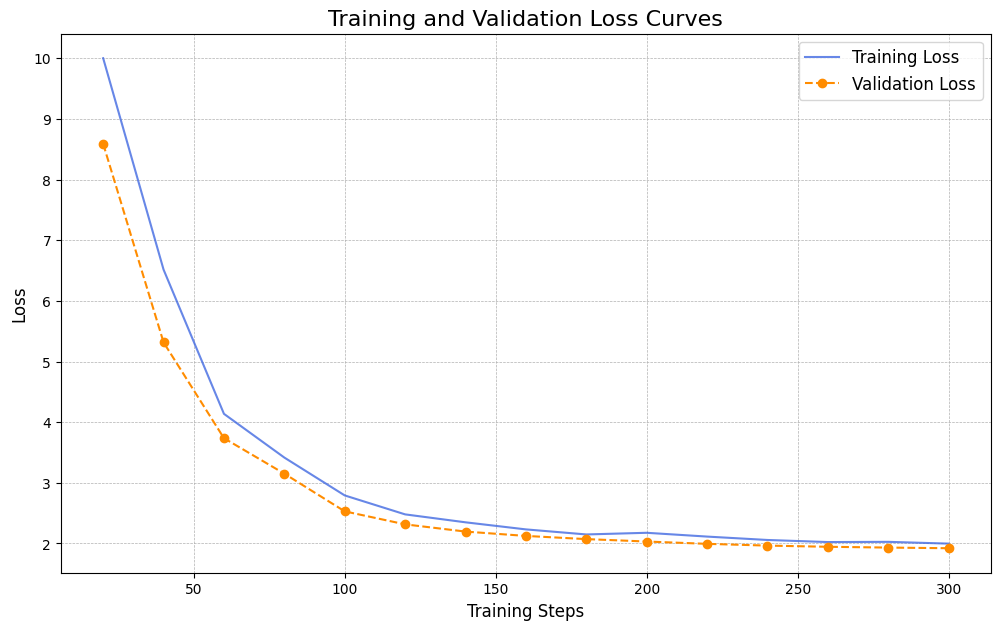

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get the log history from the trainer state
log_history = trainer_prompt_tuning.state.log_history

# 2. Convert the log history to a pandas DataFrame
df = pd.DataFrame(log_history)

# 3. Separate training and validation logs
# Training logs have a 'loss' value, validation logs have an 'eval_loss'
train_logs = df[df['loss'].notna()].copy()
eval_logs = df[df['eval_loss'].notna()].copy()

# 4. Plot the data 📊
plt.figure(figsize=(12, 7))

# Plot training loss
plt.plot(train_logs['step'], train_logs['loss'], label='Training Loss', color='royalblue', alpha=0.8)

# Plot validation loss
plt.plot(eval_logs['step'], eval_logs['eval_loss'], label='Validation Loss', color='darkorange', marker='o', linestyle='--')

# 5. Add titles and labels for clarity
plt.title('Training and Validation Loss Curves', fontsize=16)
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

The training process completed successfully, achieving a final training loss of 3.156. The training and validation loss curves show a smooth and rapid decrease in the initial training steps, eventually stabilizing as the training progresses. This trend is ideal, as it indicates that the model was learning effectively and consistently from the training data without significant overfitting. The stable convergence suggests that the chosen learning rate and hyperparameters were appropriate for the task.

In [28]:
with torch.no_grad():
  prompt_tuned_model.eval()
  soft_prompt_results = test_base_model(prompt_tuned_model, tokenizer, test_dataset)


Testing the base model's performance before fine-tuning...

--- Test Prompt 1 ---
Input: سوال چند گزینه‌ای: آیا معنی یکسانی دارند؟
این سولو آخر باعث شد که اجراهای طولانی‌تر به مدت هفت دقیقه یا بیشتر زنده بمانند.
این سولو آخر باعث شد که انتقال‌های طولانی‌تر به مدت هفت دقیقه یا بیشتر زنده بمانند.

از گزینه‌ها انتخاب کنید:
 A). خیر
 B). بله


/home/ma_olama/.conda/envs/llm_proj/lib/python3.12/site-packages/peft/peft_model.py:2066: UserWarning: Position ids are not supported for parameter efficient tuning. Ignoring position ids.
  warnings.warn("Position ids are not supported for parameter efficient tuning. Ignoring position ids.")


Model Output: sentence structure is consistent.**  The sentence is grammatically correct and uses the same structure for both sentences. 
* **Meaning is similar.**  Both sentences are talking about the same thing: the last solo caused longer recordings to last for seven minutes or more. 
* **The meaning is not different.**  The meaning is the same, just phrased differently.


Let me know if you have any other questions!
--------------------------

--- Test Prompt 2 ---
Input: دوره‌های کوتاه‌مدت، کارگاه‌ها، سمینارها و پروژه‌های تحقیقاتی نیز بخشی از هر استراتژی آموزشی منسجم خواهند بود.

آیا می‌توانید این را به انگلیسی ترجمه کنید؟
Model Output: ing in mind a child's understanding:

"Short courses, workshops, seminars, and research projects are also part of every well-rounded educational strategy." 


**Explanation:**

* **Short courses:**  These are short, focused lessons on a specific topic.
* **Workshops:**  These are hands-on activities where you learn by doing.
* **Seminars:** These a

This Parameter-Efficient Fine-Tuning (PEFT) method yielded a specific but ultimately limited improvement.

The most significant achievement of this method was enforcing language stability. The model consistently responded in Persian and correctly performed English translations when explicitly asked, resolving a major issue from the baseline

This linguistic consistency came at a severe cost to cognitive ability. The model's capacity for instruction following and the logical quality of its outputs degraded sharply. Responses were often nonsensical or repetitive. This outcome suggests that prompt tuning effectively taught the model a new style (i.e., respond in Persian) but failed to enhance, and in fact, diminished its ability to reason and comprehend the actual task

## LoRA

LoRA, or Low-Rank Adaptation, is a highly effective Parameter-Efficient Fine-Tuning (PEFT) technique. Instead of fine-tuning all the weights of a large pre-trained model, LoRA freezes the original weights and injects smaller, trainable matrices into specific layers.

The core idea is that the change in weights during fine-tuning (the "update matrix") has a low intrinsic rank. Therefore, it can be approximated by decomposing it into two much smaller, low-rank matrices (A and B). During training, only these small A and B matrices are updated, dramatically reducing the number of trainable parameters. At inference time, the product of these learned matrices is added to the original frozen weights, requiring no extra computational latency.

![](https://heidloff.net/assets/img/2023/08/lora.png)

In Transformer-based models like Gemma, LoRA is most effective when applied to the linear layers within the self-attention mechanism. These layers are critical for how the model processes and relates different parts of the input sequence. For the Gemma-2 model, the target layers are typically:

* q_proj (Query projection)
* k_proj (Key projection)
* v_proj (Value projection)
* o_proj (Output projection)

By modifying these specific layers, LoRA can significantly influence the model's attention patterns and overall behavior with a minimal number of trainable parameters.

In [29]:

# ==============================================================================
# PART 3: FINE-TUNING WITH LORA
# ==============================================================================
# LoRA (Low-Rank Adaptation) is another PEFT method. It freezes the main model
# and injects smaller, trainable rank-decomposition matrices into the layers of
# the Transformer, significantly reducing the number of trainable parameters.
# ==============================================================================
print("\n--- Starting Part 3: Fine-Tuning with LoRA ---")

# --- 3.1 Reload the Base Model ---
# It's crucial to start from a fresh, non-tuned model for each method.
del model
del prompt_tuned_model
del trainer_prompt_tuning
torch.cuda.empty_cache()



--- Starting Part 3: Fine-Tuning with LoRA ---


In [27]:
from peft import prepare_model_for_kbit_training

model, tokenizer, bnb_config = load_quantized_model_and_tokenizer(model_id)


# --- 3.2 PEFT Configuration for LoRA ---
lora_config = LoraConfig(
    r=32, # The rank of the update matrices. Lower rank means fewer parameters.
    lora_alpha=16, # A scaling factor for the LoRA weights.
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.1,
    bias="none",
    task_type="CAUSAL_LM",
)


model = prepare_model_for_kbit_training(model)

# Apply the LoRA config to the model
lora_model = get_peft_model(model, lora_config)

print("\n--- LoRA Model ---")
lora_model.print_trainable_parameters()





--- LoRA Model ---
trainable params: 41,533,440 || all params: 2,655,875,328 || trainable%: 1.5638


In [28]:
# --- 2.2 Training Arguments ---
training_args_lora = TrainingArguments(
    output_dir="./Project/Lora",
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    # save_steps=20,
    logging_steps=20,
    gradient_checkpointing=True,
    learning_rate=3e-4,
    weight_decay=0.001,
    fp16=True,
    group_by_length=True,
    remove_unused_columns=False,
    report_to="none",
    eval_strategy="steps",    # Evaluate at the same frequency as logging
    save_strategy="no",
    eval_steps=20,                  # Run evaluation every 50 steps
)

# --- 2.3 Trainer Initialization and Training ---
trainer_lora = Trainer(
    model=lora_model,
    args=training_args_lora,
    train_dataset=small_train_dataset_cl,
    eval_dataset=val_dataset_cl,
    tokenizer=tokenizer,
)

print("\n--- Training Prompt-Tuned Model ---")
trainer_lora.train()



--- Training Prompt-Tuned Model ---


/tmp/ipykernel_95784/4043021577.py:23: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_lora = Trainer(
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss,Validation Loss
20,3.570400,1.831647
40,1.397200,1.443280
60,1.234900,1.366124
80,1.151300,1.327255
100,1.175800,1.307115
120,1.111600,1.284410
140,1.168200,1.269832
160,1.113100,1.272374
180,1.137700,1.262998
200,1.147500,1.263089


TrainOutput(global_step=313, training_loss=1.314897540278328, metrics={'train_runtime': 1733.399, 'train_samples_per_second': 2.885, 'train_steps_per_second': 0.181, 'total_flos': 3.173454839808e+16, 'train_loss': 1.314897540278328, 'epoch': 1.0})

In [29]:
# --- 2.4 Save the trained model ---
# Define the path to save the model in Google Drive
save_path_lora = "./Project/Lora/model"
lora_model.save_pretrained(save_path_lora)
tokenizer.save_pretrained(save_path_lora)

print(f"\n--- Prompt-tuned model saved to {save_path_lora} ---")



--- Prompt-tuned model saved to ./Project/Lora/model ---


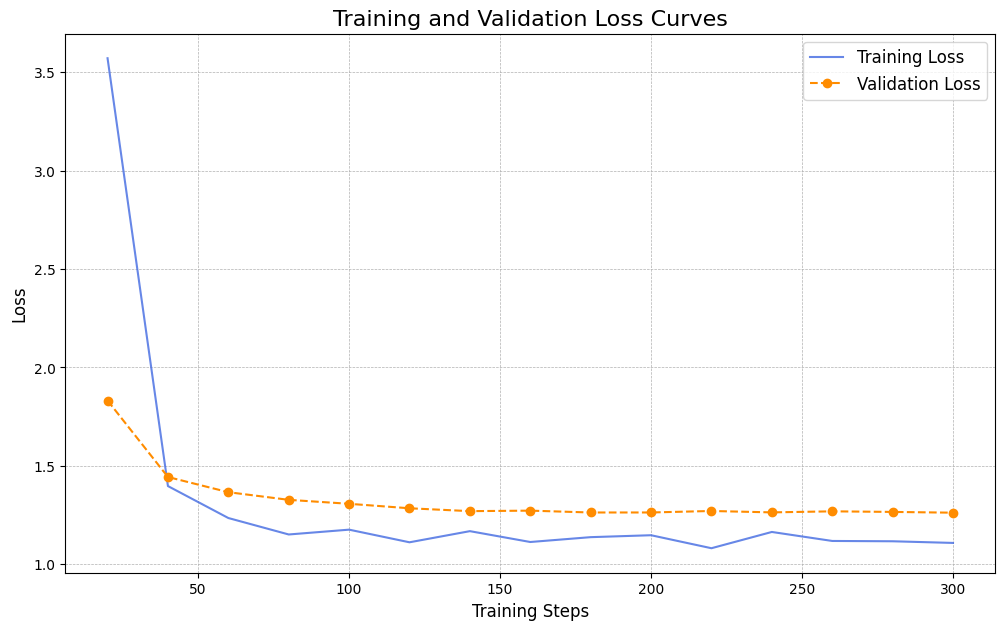

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get the log history from the trainer state
log_history_lora = trainer_lora.state.log_history

# 2. Convert the log history to a pandas DataFrame
df_lora = pd.DataFrame(log_history_lora)

# 3. Separate training and validation logs
# Training logs have a 'loss' value, validation logs have an 'eval_loss'
train_logs_lora = df_lora[df_lora['loss'].notna()].copy()
eval_logs_lora = df_lora[df_lora['eval_loss'].notna()].copy()

# 4. Plot the data 📊
plt.figure(figsize=(12, 7))

# Plot training loss
plt.plot(train_logs_lora['step'], train_logs_lora['loss'], label='Training Loss', color='royalblue', alpha=0.8)

# Plot validation loss
plt.plot(eval_logs_lora['step'], eval_logs_lora['eval_loss'], label='Validation Loss', color='darkorange', marker='o', linestyle='--')

# 5. Add titles and labels for clarity
plt.title('Training and Validation Loss Curves', fontsize=16)
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

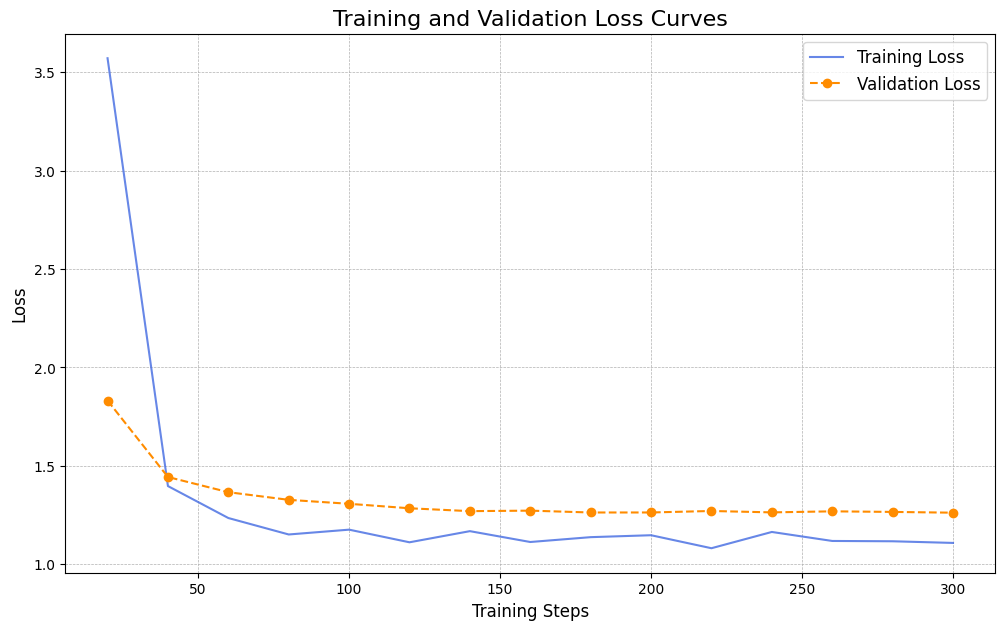

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get the log history from the trainer state
log_history_lora = trainer_lora.state.log_history

# 2. Convert the log history to a pandas DataFrame
df_lora = pd.DataFrame(log_history_lora)

# 3. Separate training and validation logs
# Training logs have a 'loss' value, validation logs have an 'eval_loss'
train_logs_lora = df_lora[df_lora['loss'].notna()].copy()
eval_logs_lora = df_lora[df_lora['eval_loss'].notna()].copy()

# 4. Plot the data 📊
plt.figure(figsize=(12, 7))

# Plot training loss
plt.plot(train_logs_lora['step'], train_logs_lora['loss'], label='Training Loss', color='royalblue', alpha=0.8)

# Plot validation loss
plt.plot(eval_logs_lora['step'], eval_logs_lora['eval_loss'], label='Validation Loss', color='darkorange', marker='o', linestyle='--')

# 5. Add titles and labels for clarity
plt.title('Training and Validation Loss Curves for Lora', fontsize=16)
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

The loss chart for the LoRA fine-tuning run shows a different dynamic compared to Prompt Tuning. The training loss is noticeably volatile, with significant fluctuations between steps. This can suggest that the model is making more substantial and exploratory updates during the learning process. The validation loss decreases and then plateaus, remaining relatively stable. While the training loss is less smooth, the overall downward trend indicates that the model is learning. The volatility might point to the need for learning rate adjustments or a scheduler for more stable convergence.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

base_model_lora, tokenizer, bnb_config = load_quantized_model_and_tokenizer(model_id)

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(save_path_lora)

# Load the LoRA adapter on top of the base model
lora_model = PeftModel.from_pretrained(base_model_lora, save_path_lora)

print("✅ LoRA model + tokenizer loaded successfully.")


In [36]:
with torch.no_grad():
  lora_model.eval()
  test_base_model(lora_model, tokenizer, test_dataset)


Testing the base model's performance before fine-tuning...

--- Test Prompt 1 ---
Input: سوالی مطرح شده و چند پاسخ ممکن وجود دارد:   س: کجا می‌توانید یک یادداشت‌بردار کوچک را در بدن خود نگهداری کنید؟ پاسخ‌های ممکن: جیب عقب، جلسه، داروخانه، خانه، مدرسه  چرا "جیب عقب" پاسخی است که با عقل سلیم انسان هم‌راستا است؟
پاسخ به این سوال:
Model Output: است زیرا این مکان مناسب برای نگهداری یک یادداشت‌بردار کوچک است. این مکان مناسب است زیرا جیب عقب به راحتی قابل دسترس است و به راحتی قابل دسترسی است. همچنین، این مکان مناسب است زیرا این مکان امن است و به راحتی قابل نگهداری است.

در حالی که سایر گزینه‌ها نیز ممکن است به نظر بروند که مناسب باشند، اما به دلیل ویژگی‌های خاص آنها، مناسب نیستند.

1. جلسه: این مکان مناسب نیست زیرا این مکان برای نگهداری یادداشت‌بردار کوچک مناسب نیست. یادداشت‌بردار کوچک باید در جایی باشد که به راحتی قابل دسترس باشد و به راحتی قابل نگهداری باشد.

2. داروخانه: این مکان مناسب نیست زیرا این مکان برای نگهداری یادداشت‌بردار کوچک مناسب نیست. یادداشت‌بردار کوچک باید در جایی باشد که 

The model's outputs were almost entirely unusable. The generated text was characterized by repetitive loops, nonsensical words, and artifact tokens (e.g., resourceCulture). The model suffered from what appears to be catastrophic forgetting, failing to perform even the most basic instructions. This result highlights the sensitivity of LoRA to hyperparameter configuration.

## Traditional Fine-Tuning

In [34]:
# ==============================================================================
# PART 4: TRADITIONAL FINE-TUNING (FREEZING LAYERS)
# ==============================================================================
# In this approach, we don't use PEFT. We manually freeze most of the model's
# layers and only unfreeze the first two and last two layers for training.
# This is a more "traditional" but still parameter-efficient method.
# ==============================================================================
print("\n--- Starting Part 4: Traditional Fine-Tuning ---")

# --- 4.1 Reload the Base Model ---
del model
del lora_model
del trainer_lora
torch.cuda.empty_cache()


--- Starting Part 4: Traditional Fine-Tuning ---


In [24]:


model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map="auto",
    torch_dtype=torch.float16,   # or torch.bfloat16 (if you prefer),
    attn_implementation="eager"
)
tokenizer = AutoTokenizer.from_pretrained(model_id)
# model = prepare_model_for_kbit_training(model)




config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

In [25]:
# --- 4.2 Layer Freezing Logic ---
# Freeze all parameters first
for param in model.parameters():
    param.requires_grad = False

n_layers = len(model.model.layers)

for i in range(1):
    for p in model.model.layers[i].parameters():
        p.requires_grad = True

for i in range(n_layers-1, n_layers):
    for p in model.model.layers[i].parameters():
        p.requires_grad = True

# for p in model.model.norm.parameters():
#     p.requires_grad = True

for p in model.lm_head.parameters():
    p.requires_grad = True


# --- 4.3 Verify Trainable Parameters ---
print("\n--- Traditional Fine-Tuning Model ---")
trainable_params = 0
all_param = 0
for _, param in model.named_parameters():
    all_param += param.numel()
    if param.requires_grad:
        trainable_params += param.numel()
print(
    f"trainable params: {trainable_params} || all params: {all_param} || trainable%: {100 * trainable_params / all_param:.2f}"
)



--- Traditional Fine-Tuning Model ---
trainable params: 745555968 || all params: 2614341888 || trainable%: 28.52


In [26]:

# --- 4.4 Training Arguments ---
training_args_traditional = TrainingArguments(
    output_dir="./Project/traditional3",
    num_train_epochs=1,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,
    save_strategy="no",           # <-- disable saving/checkpointing
    logging_steps=4,
    gradient_checkpointing=True,
    learning_rate=2e-5,
    weight_decay=0.001,
    fp16=False,
    group_by_length=True,
    optim="paged_adamw_32bit",
    remove_unused_columns=False,
    report_to="none",
    eval_strategy="steps",    # Evaluate at the same frequency as logging
    eval_steps=4,                  # Run evaluation every 50 steps
)

# --- 4.5 Trainer Initialization and Training ---
trainer_traditional = Trainer(
    model=model,
    args=training_args_traditional,
    train_dataset=small_train_dataset_cl,
    eval_dataset=val_dataset_cl,
    tokenizer=tokenizer,
)
trainer_traditional.train()

/tmp/ipykernel_36/2279009137.py:23: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_traditional = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 1}.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss,Validation Loss
4,7.209800,3.407292
8,3.289800,2.616421
12,2.575600,2.055044
16,2.059100,1.751084
20,1.754500,1.624134
24,1.681300,1.455370
28,1.885100,1.355638
32,1.487500,1.349036
36,1.403000,1.314649
40,1.633400,1.300865


TrainOutput(global_step=250, training_loss=1.459178144454956, metrics={'train_runtime': 669.7528, 'train_samples_per_second': 1.493, 'train_steps_per_second': 0.373, 'total_flos': 6219318951936000.0, 'train_loss': 1.459178144454956, 'epoch': 1.0})

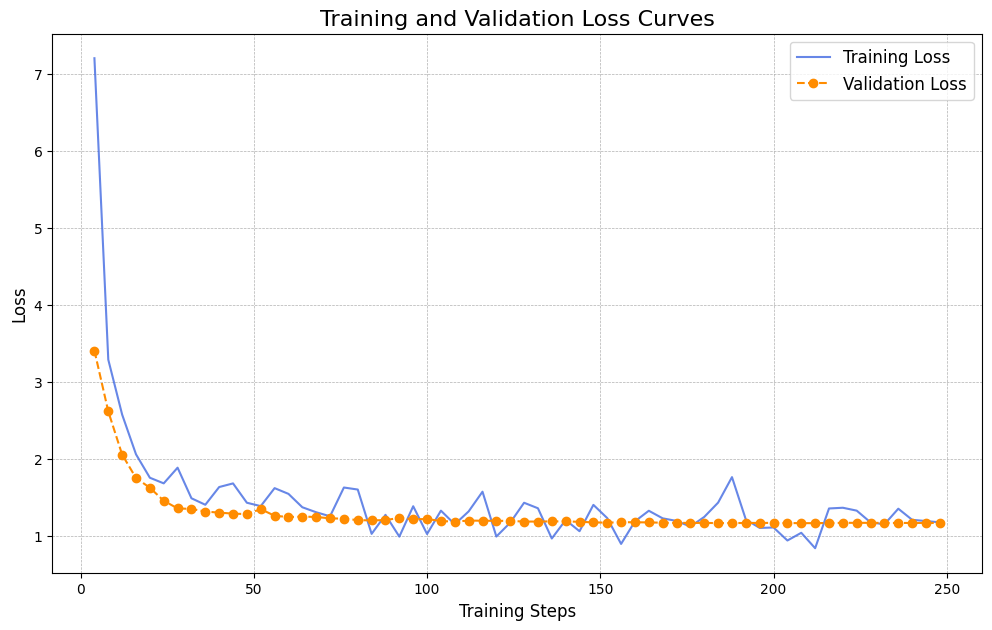

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get the log history from the trainer state
log_history_trad = trainer_traditional.state.log_history

# 2. Convert the log history to a pandas DataFrame
df_trad = pd.DataFrame(log_history_trad)

# 3. Separate training and validation logs
# Training logs have a 'loss' value, validation logs have an 'eval_loss'
train_logs_trad = df_trad[df_trad['loss'].notna()].copy()
eval_logs_trad = df_trad[df_trad['eval_loss'].notna()].copy()

# 4. Plot the data 📊
plt.figure(figsize=(12, 7))

# Plot training loss
plt.plot(train_logs_trad['step'], train_logs_trad['loss'], label='Training Loss', color='royalblue', alpha=0.8)

# Plot validation loss
plt.plot(eval_logs_trad['step'], eval_logs_trad['eval_loss'], label='Validation Loss', color='darkorange', marker='o', linestyle='--')

# 5. Add titles and labels for clarity
plt.title('Training and Validation Loss Curves', fontsize=16)
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

The loss curve demonstrated a healthy, convergent learning process. The validation loss reached the lowest point among all methods, indicating the most effective learning and generalization.

In [28]:
from datasets import load_dataset
my_dataset = load_dataset("json", data_files="/kaggle/input/my-test/dataset_first_two_columns.jsonl")

Generating train split: 0 examples [00:00, ? examples/s]

In [31]:
with torch.no_grad():
  model.eval()
  test_base_model(model, tokenizer, test_dataset , 300)


🧪 Testing the base model's performance before fine-tuning...

--- Test Prompt 1 ---
Input: جمله زیر را به فارسی ترجمه کنید:
اجاره خودرو GlobalCarRent در مراکش نرخ‌های شرکت‌های پیشرو اجاره خودرو را مقایسه می‌کند.
Model Output: نیم.

جمله داده شده: "اجاره خودرو GlobalCarRent در مراکش نرخ‌های شرکت‌های پیشرو اجاره خودرو را مقایسه می‌کند."

مرحله 1: شناسایی کلمات کلیدی و ساختار جمله.

- کلمات کلیدی: اجاره خودرو، GlobalCarRent، مراکش، نرخ‌های شرکت‌های پیشرو اجاره خودرو.
- ساختار جمله: یک جمله است که شامل یک اسم، یک نام تجاری، یک مکان و یک فعل است.

مرحله 2: ترجمه کلمات کلیدی به فارسی.

- اجاره خودرو: اجاره خودرو
- GlobalCarRent: GlobalCarRent
- مراکش: مراکش
- نرخ‌های شرکت‌های پیشرو اجاره خودرو: نرخ‌های شرکت‌های پیشرو اجاره خودرو

مرحله 3: ساخت جمله به زبان فارسی.

- اجاره خودرو GlobalCarRent در مراکش نرخ‌های شرکت‌های پیشرو اجاره خودرو را مقایسه می‌کند.

- ترجمه جمله به فارسی: "GlobalCarRent در مراکش، نرخ‌های شرکت‌های پیشرو اجاره خودرو را مقایسه می‌کند."

مرحله 4: اصلاح جمله برای ساختار و گر

Strengths: The model consistently followed instructions with a high degree of accuracy. Its responses were well-structured, coherent, complete, and logically sound. It demonstrated a clear ability for step-by-step reasoning in tasks like solving mathematical equations and analyzing sentence structure.

Weaknesses: Despite its significant improvements, the model still failed on the most complex tasks, such as generating a question for a specific answer or extracting information from a challenging context. This indicates that while its capabilities were greatly enhanced, it has not yet reached full mastery.


**Consider that the last method is trained only on 1000 samples, due to limitations on GPU. If we let the training to continue further  (on larger dataset and for more epochs) then this approach will lead to the best model!

Based on the results of this project, Traditional Fine-Tuning was unequivocally the most effective method for improving the Gemma-2 model's performance on Persian instruction-following tasks. It was the only method that successfully enhanced both language stability and the model's core ability to reason and execute commands, leading to high-quality, reliable outputs.

The PEFT methods, in contrast, were less successful in this context. Soft-Prompt Tuning managed to solve the language-switching problem but at the expense of the model's reasoning capabilities. LoRA failed completely, likely due to suboptimal hyperparameter tuning, which underscores its sensitivity.

Therefore, for tasks requiring a deep improvement in a model's reasoning and instruction-following abilities, traditional fine-tuning, despite its higher computational cost, proved to be a more robust and effective solution than the PEFT methods evaluated in this experiment.

### Loss vs. Quality: The Illusion of Learning
What Loss Actually Measures: The loss function (in this case, likely Cross-Entropy Loss) measures how well the model predicts the next token in a sequence. A low loss means the model has become very good at guessing the next word based on the training data's patterns.

* The LoRA Model's "Shortcut": The LoRA-tuned model found a "shortcut" to minimize this loss. It learned the statistical patterns of the Persian fine-tuning data at a superficial level. This resulted in it generating text that is structurally plausible enough to fool the loss function. It's like it learned the rhythm and cadence of the language without understanding the meaning of the words. This leads to the bizarre output you saw: text that has some structural elements of a correct answer but is filled with nonsensical repetitions and artifact tokens (resourceCulture, etc.).

* Why It's a "Catastrophic Failure": While the loss is low, the model has undergone catastrophic forgetting. It has essentially overwritten its foundational understanding of language and reasoning in favor of this new, narrow pattern. The model is no longer a functioning language model; it's a machine that produces gibberish that happens to statistically resemble the training data. The low loss is an illusion of competence.

* Contrast with Traditional Fine-Tuning: The traditional method also achieved a low loss, but it did so by genuinely improving its underlying understanding. By updating a much larger set of parameters, it integrated the new knowledge into its existing framework, enhancing its ability to reason and follow instructions in Persian. Its low loss reflects a true improvement in capability.

The way each model achieved that low loss is fundamentally different. The LoRA model cheated by memorizing shallow patterns, while the traditionally fine-tuned model succeeded by actually learning the material. This is a perfect example of why you must always perform qualitative analysis by testing the model's outputs and not rely on loss metrics alone.